In [ ]:
!pip install pandas numpy matplotlib seaborn nltk scikit-learn wordcloud

### Import libraries

In [ ]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# NLP preprocessing
import nltk
import re

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
!pip install datasets

In [ ]:
from datasets import load_dataset

# Load the dataset
dataset = load_dataset(
    "chibifire/kaggle-womens-ecom-clothing-reviews",
    split="train"
)

# Convert into Pandas DataFrame
df = dataset.to_pandas()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# Display first five rows
df.head()

,row_id,clothing_id,age,rating,recommended_ind,positive_feedback_count,title,review_text,division_name,department_name,class_name
0,0,767,33,4,1,0,None,Absolutely wonderful - silky and sexy and comf...,Initmates,Intimate,Intimates
1,1,1080,34,5,1,4,None,Love this dress! it's sooo pretty. i happene...,General,Dresses,Dresses
2,2,1077,60,3,0,0,Some major design flaws,I had such high hopes for this dress and reall...,General,Dresses,Dresses
3,3,1049,50,5,1,0,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",General Petite,Bottoms,Pants
4,4,847,47,5,1,6,Flattering shirt,This shirt is very flattering to all due to th...,General,Tops,Blouses


In [ ]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (23486, 11)

Column Names:
['row_id', 'clothing_id', 'age', 'rating', 'recommended_ind', 'positive_feedback_count', 'title', 'review_text', 'division_name', 'department_name', 'class_name']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   row_id                   23486 non-null  int64 
 1   clothing_id              23486 non-null  int32 
 2   age                      23486 non-null  int32 
 3   rating                   23486 non-null  int8  
 4   recommended_ind          23486 non-null  int8  
 5   positive_feedback_count  23486 non-null  int32 
 6   title                    19676 non-null  object
 7   review_text              22641 non-null  object
 8   division_name            23472 non-null  object
 9   department_name          23472 non-null  object
 10  class_name             

In [ ]:
df[['review_text', 'rating']].head(10)

,review_text,rating
0,Absolutely wonderful - silky and sexy and comf...,4
1,Love this dress! it's sooo pretty. i happene...,5
2,I had such high hopes for this dress and reall...,3
3,"I love, love, love this jumpsuit. it's fun, fl...",5
4,This shirt is very flattering to all due to th...,5
5,"I love tracy reese dresses, but this one is no...",2
6,I aded this in my basket at hte last mintue to...,5
7,"I ordered this in carbon for store pick up, an...",4
8,I love this dress. i usually get an xs but it ...,5
9,"I'm 5""5' and 125 lbs. i ordered the s petite t...",5


In [ ]:
def assign_sentiment(rating):

    if rating <= 2:
        return "Negative"

    elif rating == 3:
        return "Neutral"

    else:
        return "Positive"


# Create a new sentiment column
df['sentiment'] = df['rating'].apply(assign_sentiment)

# Display sample results
df[['review_text', 'rating', 'sentiment']].head(10)

,review_text,rating,sentiment
0,Absolutely wonderful - silky and sexy and comf...,4,Positive
1,Love this dress! it's sooo pretty. i happene...,5,Positive
2,I had such high hopes for this dress and reall...,3,Neutral
3,"I love, love, love this jumpsuit. it's fun, fl...",5,Positive
4,This shirt is very flattering to all due to th...,5,Positive
5,"I love tracy reese dresses, but this one is no...",2,Negative
6,I aded this in my basket at hte last mintue to...,5,Positive
7,"I ordered this in carbon for store pick up, an...",4,Positive
8,I love this dress. i usually get an xs but it ...,5,Positive
9,"I'm 5""5' and 125 lbs. i ordered the s petite t...",5,Positive


In [ ]:
df.to_csv("sentiment_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:
print("Total number of rows:", df.shape[0])
print("Total number of columns:", df.shape[1])

Total number of rows: 23486
Total number of columns: 12


In [ ]:
print("Columns in the dataset:\n")

for column in df.columns:
    print(column)

Columns in the dataset:

row_id
clothing_id
age
rating
recommended_ind
positive_feedback_count
title
review_text
division_name
department_name
class_name
sentiment


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   row_id                   23486 non-null  int64 
 1   clothing_id              23486 non-null  int32 
 2   age                      23486 non-null  int32 
 3   rating                   23486 non-null  int8  
 4   recommended_ind          23486 non-null  int8  
 5   positive_feedback_count  23486 non-null  int32 
 6   title                    19676 non-null  object
 7   review_text              22641 non-null  object
 8   division_name            23472 non-null  object
 9   department_name          23472 non-null  object
 10  class_name               23472 non-null  object
 11  sentiment                23486 non-null  object
dtypes: int32(3), int64(1), int8(2), object(6)
memory usage: 1.6+ MB


In [ ]:
print("Missing values in each column:\n")

print(df.isnull().sum())

Missing values in each column:

row_id                        0
clothing_id                   0
age                           0
rating                        0
recommended_ind               0
positive_feedback_count       0
title                      3810
review_text                 845
division_name                14
department_name              14
class_name                   14
sentiment                     0
dtype: int64


In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

row_id                      0.000000
clothing_id                 0.000000
age                         0.000000
rating                      0.000000
recommended_ind             0.000000
positive_feedback_count     0.000000
title                      16.222430
review_text                 3.597888
division_name               0.059610
department_name             0.059610
class_name                  0.059610
sentiment                   0.000000
dtype: float64


In [ ]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [ ]:
print(df['sentiment'].value_counts())

sentiment
Positive    18208
Neutral      2871
Negative     2407
Name: count, dtype: int64


['row_id', 'clothing_id', 'age', 'rating', 'recommended_ind', 'positive_feedback_count', 'title', 'review_text', 'division_name', 'department_name', 'class_name', 'sentiment']


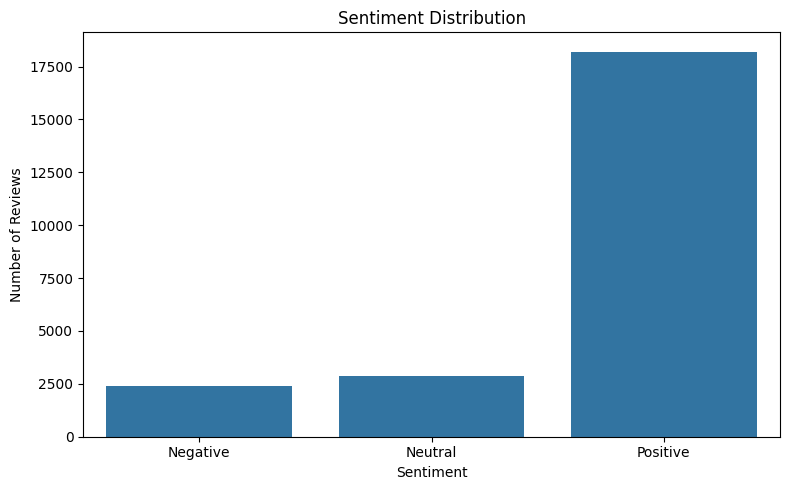

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Check if sentiment column exists
print(df.columns.tolist())

# Plot sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='sentiment',
    order=['Negative', 'Neutral', 'Positive']
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

In [ ]:
print("Rating Distribution:\n")

print(df['rating'].value_counts().sort_index())

Rating Distribution:

rating
1      842
2     1565
3     2871
4     5077
5    13131
Name: count, dtype: int64


['row_id', 'clothing_id', 'age', 'rating', 'recommended_ind', 'positive_feedback_count', 'title', 'review_text', 'division_name', 'department_name', 'class_name']


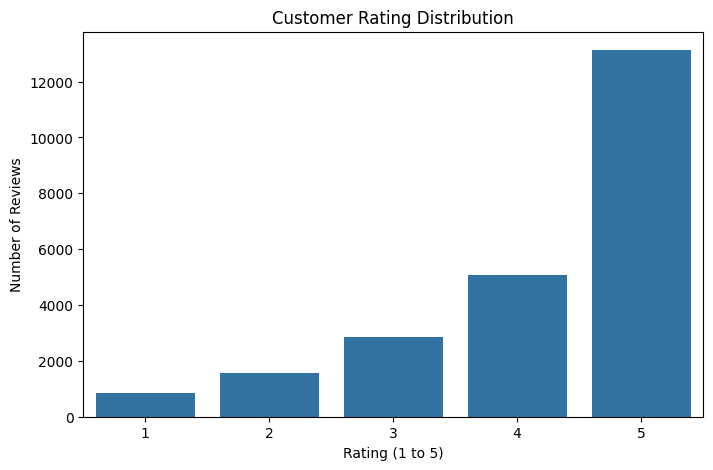

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

# Load dataset
dataset = load_dataset(
    "chibifire/kaggle-womens-ecom-clothing-reviews",
    split="train"
)

# Convert dataset into DataFrame
df = dataset.to_pandas()

# Check rating column
print(df.columns.tolist())

# Plot rating distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='rating')

plt.title("Customer Rating Distribution")
plt.xlabel("Rating (1 to 5)")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
# Check available columns
print(df.columns.tolist())

['row_id', 'clothing_id', 'age', 'rating', 'recommended_ind', 'positive_feedback_count', 'title', 'review_text', 'division_name', 'department_name', 'class_name']


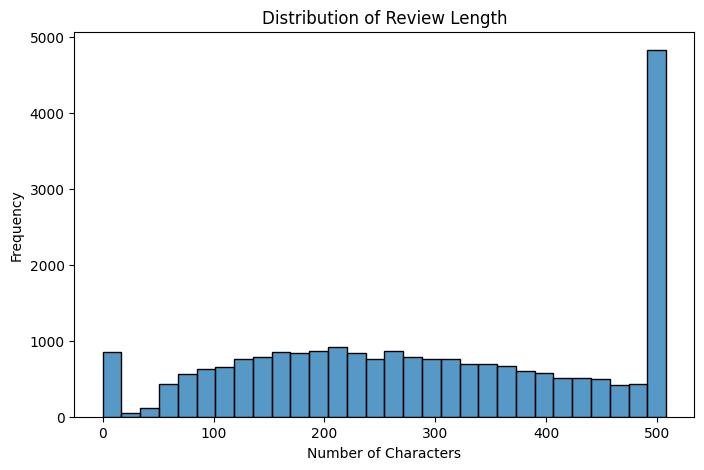

In [ ]:
# Calculate review length
df['review_length'] = df['review_text'].fillna('').astype(str).apply(len)

# Plot review length distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='review_length',
    bins=30
)

plt.title("Distribution of Review Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.show()

In [ ]:
# Create sentiment column
def assign_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df['sentiment'] = df['rating'].apply(assign_sentiment)

# Create review length column
df['review_length'] = df['review_text'].fillna('').astype(str).apply(len)

# EDA Summary
print("========== EDA SUMMARY ==========")

print("Total Reviews:", len(df))

print("\nSentiment Counts:")
print(df['sentiment'].value_counts())

print("\nSentiment Percentages:")
print(df['sentiment'].value_counts(normalize=True) * 100)

print("\nMissing Review Text:", df['review_text'].isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nAverage Review Length:", df['review_length'].mean())

print("\nEDA Completed Successfully!")

========== EDA SUMMARY ==========
Total Reviews: 23486

Sentiment Counts:
sentiment
Positive    18208
Neutral      2871
Negative     2407
Name: count, dtype: int64

Sentiment Percentages:
sentiment
Positive    77.527037
Neutral     12.224304
Negative    10.248659
Name: proportion, dtype: float64

Missing Review Text: 845

Duplicate Rows: 0

Average Review Length: 297.581665673167

EDA Completed Successfully!


### Install and import NLP libraries

In [ ]:
!pip install nltk

In [ ]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

### Download required NLTK resources

In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")

NLTK resources downloaded successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [ ]:
# Remove rows with missing review text or sentiment
df = df.dropna(subset=['review_text', 'sentiment'])

print("Missing reviews removed!")
print("Remaining records:", len(df))

Missing reviews removed!
Remaining records: 22641


In [ ]:
# Remove duplicate rows
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

print("Duplicate records removed!")
print("Remaining records:", len(df))

Duplicate records removed!
Remaining records: 22641


In [ ]:
#convert text to lowercase
df['review_text'] = df['review_text'].str.lower()

print(df['review_text'].head())

0    absolutely wonderful - silky and sexy and comf...
1    love this dress!  it's sooo pretty.  i happene...
2    i had such high hopes for this dress and reall...
3    i love, love, love this jumpsuit. it's fun, fl...
4    this shirt is very flattering to all due to th...
Name: review_text, dtype: object


In [ ]:
def clean_text(text):

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


df['cleaned_text'] = df['review_text'].apply(clean_text)

print(df[['review_text', 'cleaned_text']].head(10))

                                         review_text  \
0  absolutely wonderful - silky and sexy and comf...   
1  love this dress!  it's sooo pretty.  i happene...   
2  i had such high hopes for this dress and reall...   
3  i love, love, love this jumpsuit. it's fun, fl...   
4  this shirt is very flattering to all due to th...   
5  i love tracy reese dresses, but this one is no...   
6  i aded this in my basket at hte last mintue to...   
7  i ordered this in carbon for store pick up, an...   
8  i love this dress. i usually get an xs but it ...   
9  i'm 5"5' and 125 lbs. i ordered the s petite t...   

                                        cleaned_text  
0  absolutely wonderful silky and sexy and comfor...  
1  love this dress its sooo pretty i happened to ...  
2  i had such high hopes for this dress and reall...  
3  i love love love this jumpsuit its fun flirty ...  
4  this shirt is very flattering to all due to th...  
5  i love tracy reese dresses but this one is not... 

In [ ]:
#tokenization
df['tokens'] = df['cleaned_text'].apply(word_tokenize)

print(df[['cleaned_text', 'tokens']].head())

                                        cleaned_text  \
0  absolutely wonderful silky and sexy and comfor...   
1  love this dress its sooo pretty i happened to ...   
2  i had such high hopes for this dress and reall...   
3  i love love love this jumpsuit its fun flirty ...   
4  this shirt is very flattering to all due to th...   

                                              tokens  
0  [absolutely, wonderful, silky, and, sexy, and,...  
1  [love, this, dress, its, sooo, pretty, i, happ...  
2  [i, had, such, high, hopes, for, this, dress, ...  
3  [i, love, love, love, this, jumpsuit, its, fun...  
4  [this, shirt, is, very, flattering, to, all, d...  


In [ ]:
#stop word removal

# Get English stopwords
stop_words = set(stopwords.words('english'))

# Preserve important negation words
stop_words = stop_words - {'not', 'no', 'nor'}

def remove_stopwords(tokens):

    return [
        word for word in tokens
        if word not in stop_words
    ]


df['tokens'] = df['tokens'].apply(remove_stopwords)

print(df[['cleaned_text', 'tokens']].head())

                                        cleaned_text  \
0  absolutely wonderful silky and sexy and comfor...   
1  love this dress its sooo pretty i happened to ...   
2  i had such high hopes for this dress and reall...   
3  i love love love this jumpsuit its fun flirty ...   
4  this shirt is very flattering to all due to th...   

                                              tokens  
0  [absolutely, wonderful, silky, sexy, comfortable]  
1  [love, dress, sooo, pretty, happened, find, st...  
2  [high, hopes, dress, really, wanted, work, ini...  
3  [love, love, love, jumpsuit, fun, flirty, fabu...  
4  [shirt, flattering, due, adjustable, front, ti...  


In [ ]:
#lemmetization
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

nltk.download('averaged_perceptron_tagger_eng')

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(word):

    tag = nltk.pos_tag([word])[0][1][0].upper()

    tag_dict = {
        'J': wordnet.ADJ,
        'N': wordnet.NOUN,
        'V': wordnet.VERB,
        'R': wordnet.ADV
    }

    return tag_dict.get(tag, wordnet.NOUN)


def lemmatize_words(tokens):

    return [
        lemmatizer.lemmatize(word, get_wordnet_pos(word))
        for word in tokens
    ]


df['tokens'] = df['tokens'].apply(lemmatize_words)

print(df[['cleaned_text', 'tokens']].head())

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


                                        cleaned_text  \
0  absolutely wonderful silky and sexy and comfor...   
1  love this dress its sooo pretty i happened to ...   
2  i had such high hopes for this dress and reall...   
3  i love love love this jumpsuit its fun flirty ...   
4  this shirt is very flattering to all due to th...   

                                              tokens  
0  [absolutely, wonderful, silky, sexy, comfortable]  
1  [love, dress, sooo, pretty, happen, find, stor...  
2  [high, hope, dress, really, want, work, initia...  
3  [love, love, love, jumpsuit, fun, flirty, fabu...  
4  [shirt, flatter, due, adjustable, front, tie, ...  


In [ ]:
# Convert tokens back into sentences
df['processed_text'] = df['tokens'].apply(
    lambda tokens: ' '.join(tokens)
)

print(df[['review_text', 'processed_text']].head(10))

                                         review_text  \
0  absolutely wonderful - silky and sexy and comf...   
1  love this dress!  it's sooo pretty.  i happene...   
2  i had such high hopes for this dress and reall...   
3  i love, love, love this jumpsuit. it's fun, fl...   
4  this shirt is very flattering to all due to th...   
5  i love tracy reese dresses, but this one is no...   
6  i aded this in my basket at hte last mintue to...   
7  i ordered this in carbon for store pick up, an...   
8  i love this dress. i usually get an xs but it ...   
9  i'm 5"5' and 125 lbs. i ordered the s petite t...   

                                      processed_text  
0        absolutely wonderful silky sexy comfortable  
1  love dress sooo pretty happen find store im gl...  
2  high hope dress really want work initially ord...  
3  love love love jumpsuit fun flirty fabulous ev...  
4  shirt flatter due adjustable front tie perfect...  
5  love tracy reese dress one not petite foot tal... 

In [ ]:
#compare before and after preprocessing
for i in range(5):

    print("Original Review:")
    print(df['review_text'].iloc[i])

    print("\nProcessed Review:")
    print(df['processed_text'].iloc[i])

    print("-" * 60)

Original Review:
absolutely wonderful - silky and sexy and comfortable

Processed Review:
absolutely wonderful silky sexy comfortable
------------------------------------------------------------
Original Review:
love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i bought a petite and am 5'8".  i love the length on me- hits just a little below the knee.  would definitely be a true midi on someone who is truly petite.

Processed Review:
love dress sooo pretty happen find store im glad bc never would order online bc petite bought petite love length hit little knee would definitely true midi someone truly petite
------------------------------------------------------------
Original Review:
i had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it

In [ ]:
#final preprocessing check
print("========== PREPROCESSING SUMMARY ==========")

print("Total Records:", len(df))

print("Missing Processed Text:",
      df['processed_text'].isnull().sum())

print("Empty Processed Reviews:",
      (df['processed_text'].str.strip() == '').sum())

print("\nSample Processed Reviews:")
print(df['processed_text'].head())

print("\nPreprocessing Completed Successfully!")

========== PREPROCESSING SUMMARY ==========
Total Records: 22641
Missing Processed Text: 0
Empty Processed Reviews: 0

Sample Processed Reviews:
0          absolutely wonderful silky sexy comfortable
1    love dress sooo pretty happen find store im gl...
2    high hope dress really want work initially ord...
3    love love love jumpsuit fun flirty fabulous ev...
4    shirt flatter due adjustable front tie perfect...
Name: processed_text, dtype: object

Preprocessing Completed Successfully!


In [ ]:
#empty processed reviews should be removed(they contain no extra information)
df = df[df['processed_text'].str.strip() != '']

df = df.reset_index(drop=True)

print("Final dataset shape:", df.shape)

Final dataset shape: (22641, 16)


In [ ]:
# Save the preprocessed dataset
df.to_csv("preprocessed_sentiment_data.csv", index=False)

print("Preprocessed dataset saved successfully!")
print("Total records:", len(df))
print("Total columns:", len(df.columns))

Preprocessed dataset saved successfully!
Total records: 22641
Total columns: 16


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

print("Feature extraction libraries imported successfully!")

Feature extraction libraries imported successfully!


In [ ]:
# Input variable
X = df['processed_text']

# Output variable
y = df['sentiment']

print("Input data:")
print(X.head())

print("\nTarget data:")
print(y.head())

Input data:
0          absolutely wonderful silky sexy comfortable
1    love dress sooo pretty happen find store im gl...
2    high hope dress really want work initially ord...
3    love love love jumpsuit fun flirty fabulous ev...
4    shirt flatter due adjustable front tie perfect...
Name: processed_text, dtype: object

Target data:
0    Positive
1    Positive
2     Neutral
3    Positive
4    Positive
Name: sentiment, dtype: object


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 18112
Testing records: 4529


In [ ]:
# Create Bag of Words vectorizer
bow = CountVectorizer(max_features=5000)

# Learn vocabulary from training data
X_train_bow = bow.fit_transform(X_train)

# Convert testing data using the same vocabulary
X_test_bow = bow.transform(X_test)

print("Bag of Words completed!")

print("Training shape:", X_train_bow.shape)
print("Testing shape:", X_test_bow.shape)

Bag of Words completed!
Training shape: (18112, 5000)
Testing shape: (4529, 5000)


In [ ]:
# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Learn vocabulary and transform training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF extraction completed!")

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

TF-IDF extraction completed!
Training shape: (18112, 5000)
Testing shape: (4529, 5000)


In [ ]:
# Get feature names
feature_names = tfidf.get_feature_names_out()

# Display first 20 words
print("First 20 extracted features:")

print(feature_names[:20])

First 20 extracted features:
['aa' 'ab' 'abbey' 'abby' 'abdomen' 'ability' 'able' 'abnormally' 'abo'
 'abou' 'abroad' 'absolute' 'absolutely' 'absolutley' 'absolutly'
 'abstract' 'absurd' 'abt' 'abundance' 'ac']


In [ ]:
# Convert first 5 training reviews into a DataFrame
tfidf_df = pd.DataFrame(
    X_train_tfidf[:5].toarray(),
    columns=feature_names
)

print(tfidf_df.head())

    aa   ab  abbey  abby  abdomen  ability  able  abnormally  abo  abou  ...  \
0  0.0  0.0    0.0   0.0      0.0      0.0   0.0         0.0  0.0   0.0  ...   
1  0.0  0.0    0.0   0.0      0.0      0.0   0.0         0.0  0.0   0.0  ...   
2  0.0  0.0    0.0   0.0      0.0      0.0   0.0         0.0  0.0   0.0  ...   
3  0.0  0.0    0.0   0.0      0.0      0.0   0.0         0.0  0.0   0.0  ...   
4  0.0  0.0    0.0   0.0      0.0      0.0   0.0         0.0  0.0   0.0  ...   

   zag  zero  zig  zigzag  zillion  zip  zipped  zipper  zone  zoom  
0  0.0   0.0  0.0     0.0      0.0  0.0     0.0     0.0   0.0   0.0  
1  0.0   0.0  0.0     0.0      0.0  0.0     0.0     0.0   0.0   0.0  
2  0.0   0.0  0.0     0.0      0.0  0.0     0.0     0.0   0.0   0.0  
3  0.0   0.0  0.0     0.0      0.0  0.0     0.0     0.0   0.0   0.0  
4  0.0   0.0  0.0     0.0      0.0  0.0     0.0     0.0   0.0   0.0  

[5 rows x 5000 columns]


In [ ]:
print("========== FEATURE EXTRACTION COMPARISON ==========")

print("Bag of Words:")
print("Training shape:", X_train_bow.shape)
print("Testing shape:", X_test_bow.shape)

print("\nTF-IDF:")
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

========== FEATURE EXTRACTION COMPARISON ==========
Bag of Words:
Training shape: (18112, 5000)
Testing shape: (4529, 5000)

TF-IDF:
Training shape: (18112, 5000)
Testing shape: (4529, 5000)


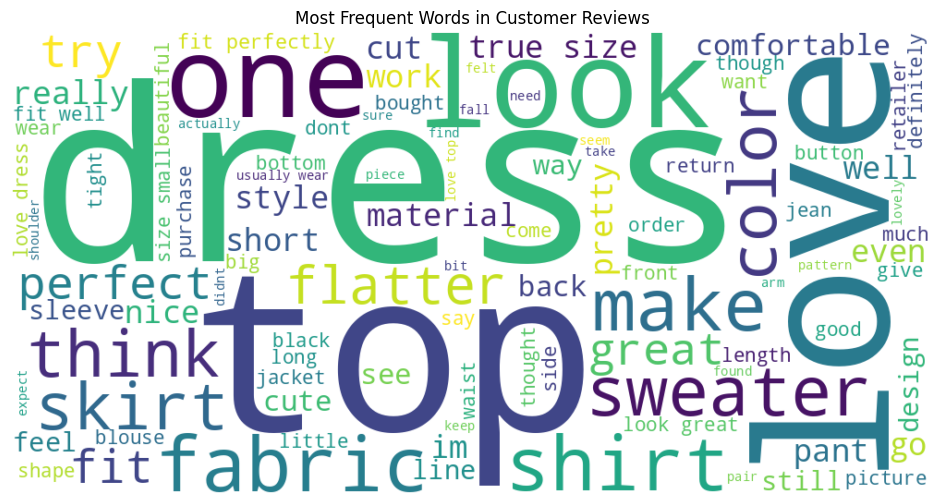

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Combine all processed reviews
all_words = ' '.join(df['processed_text'])

# Generate word cloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(all_words)

# Display word cloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Most Frequent Words in Customer Reviews")
plt.show()

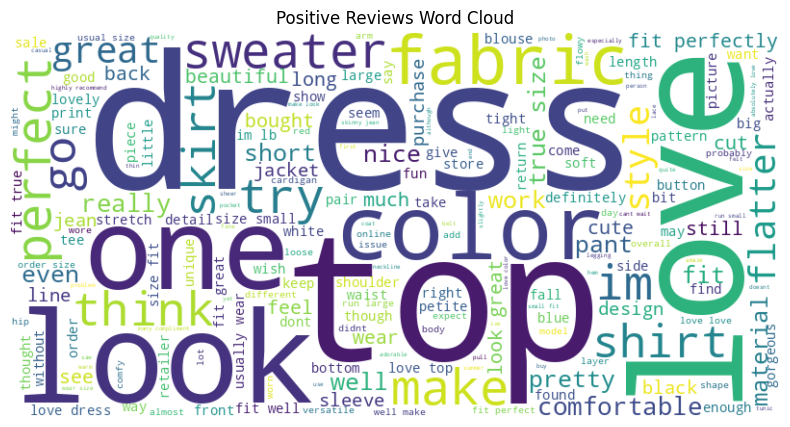

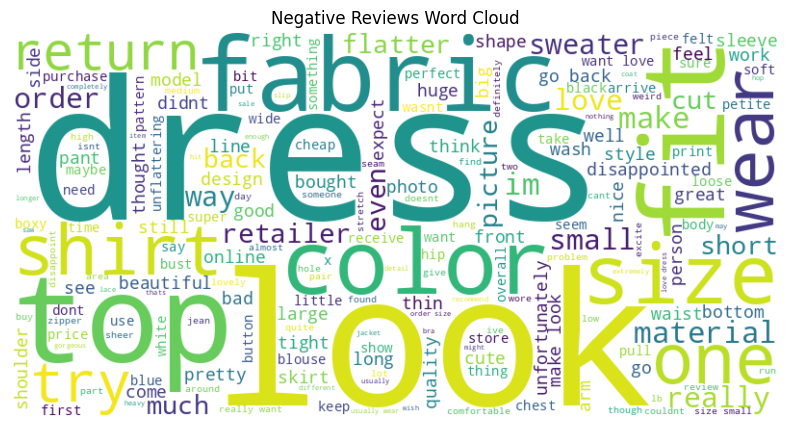

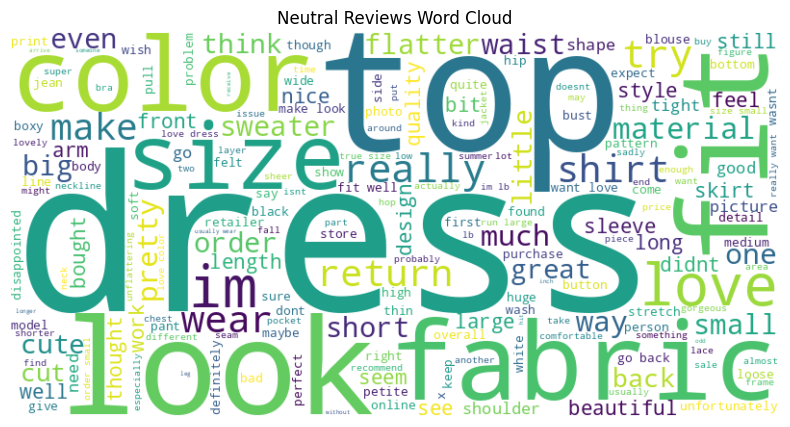

In [ ]:
sentiments = ['Positive', 'Negative', 'Neutral']

for sentiment in sentiments:

    text = ' '.join(
        df[df['sentiment'] == sentiment]['processed_text']
    )

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white'
    ).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(sentiment + " Reviews Word Cloud")
    plt.show()

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

print("Machine learning models imported successfully!")

Machine learning models imported successfully!


In [ ]:
# Create Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Predict sentiments
nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [ ]:
# Create Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict sentiments
lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Create SVM model
svm_model = LinearSVC(
    class_weight='balanced',
    random_state=42
)

# Train the model
svm_model.fit(X_train_tfidf, y_train)

# Predict sentiments
svm_predictions = svm_model.predict(X_test_tfidf)

print("SVM model trained successfully!")

SVM model trained successfully!


In [ ]:
print("========== MODEL TRAINING RESULTS ==========")

print("Naive Bayes: Completed")
print("Logistic Regression: Completed")
print("SVM: Completed")

print("\nAll three models trained successfully!")

========== MODEL TRAINING RESULTS ==========
Naive Bayes: Completed
Logistic Regression: Completed
SVM: Completed

All three models trained successfully!


In [ ]:
from sklearn.metrics import accuracy_score

nb_accuracy = accuracy_score(y_test, nb_predictions)
lr_accuracy = accuracy_score(y_test, lr_predictions)
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("Naive Bayes Accuracy:", nb_accuracy * 100, "%")
print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")
print("SVM Accuracy:", svm_accuracy * 100, "%")

Naive Bayes Accuracy: 77.67719143298741 %
Logistic Regression Accuracy: 76.17575623758003 %
SVM Accuracy: 79.64230514462353 %


In [ ]:
from sklearn.metrics import classification_report

print("NAIVE BAYES REPORT")
print(classification_report(y_test, nb_predictions))

print("\nLOGISTIC REGRESSION REPORT")
print(classification_report(y_test, lr_predictions))

print("\nSVM REPORT")
print(classification_report(y_test, svm_predictions))

NAIVE BAYES REPORT
              precision    recall  f1-score   support

    Negative       0.74      0.05      0.09       474
     Neutral       0.50      0.01      0.02       565
    Positive       0.78      1.00      0.87      3490

    accuracy                           0.78      4529
   macro avg       0.67      0.35      0.33      4529
weighted avg       0.74      0.78      0.69      4529


LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

    Negative       0.45      0.61      0.52       474
     Neutral       0.32      0.48      0.38       565
    Positive       0.95      0.83      0.89      3490

    accuracy                           0.76      4529
   macro avg       0.57      0.64      0.60      4529
weighted avg       0.82      0.76      0.78      4529


SVM REPORT
              precision    recall  f1-score   support

    Negative       0.49      0.54      0.52       474
     Neutral       0.35      0.37      0.36       565
    Positive    

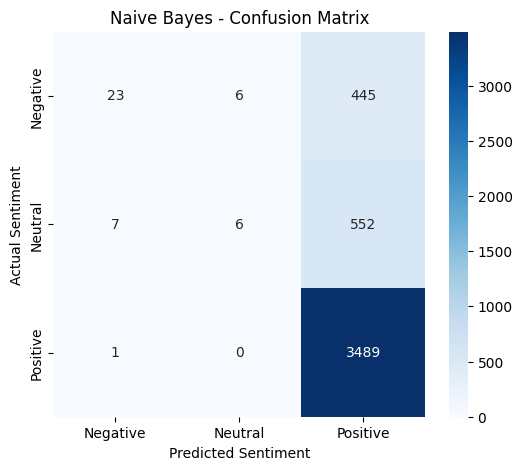

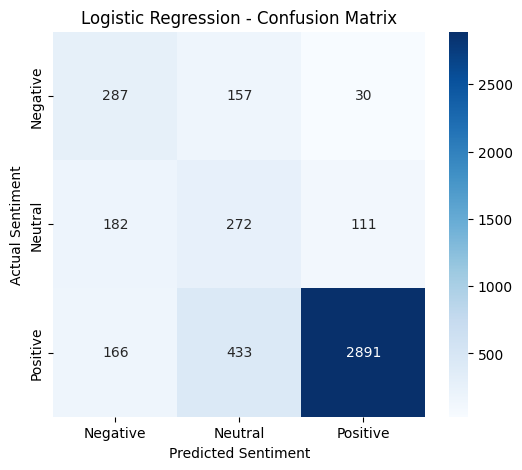

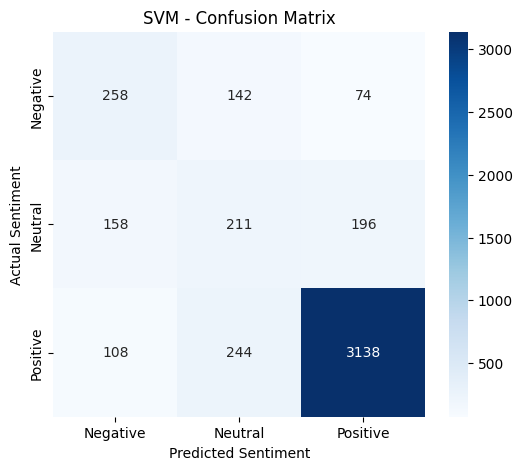

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

models = {
    "Naive Bayes": nb_predictions,
    "Logistic Regression": lr_predictions,
    "SVM": svm_predictions
}

for name, predictions in models.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=['Negative', 'Neutral', 'Positive']
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Neutral', 'Positive'],
        yticklabels=['Negative', 'Neutral', 'Positive']
    )

    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")

    plt.show()

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Naive Bayes',
        'Logistic Regression',
        'SVM'
    ],

    'Accuracy': [
        nb_accuracy,
        lr_accuracy,
        svm_accuracy
    ],

    'F1 Score': [
        classification_report(
            y_test, nb_predictions,
            output_dict=True
        )['macro avg']['f1-score'],

        classification_report(
            y_test, lr_predictions,
            output_dict=True
        )['macro avg']['f1-score'],

        classification_report(
            y_test, svm_predictions,
            output_dict=True
        )['macro avg']['f1-score']
    ]
})

print(results.sort_values(
    by='F1 Score',
    ascending=False
))

                 Model  Accuracy  F1 Score
2                  SVM  0.796423  0.596677
1  Logistic Regression  0.761758  0.595114
0          Naive Bayes  0.776772  0.328920


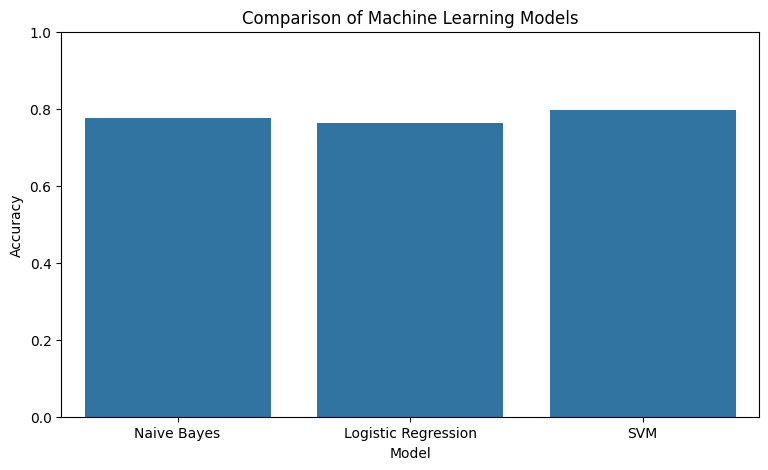

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

In [ ]:
best_model_name = results.loc[
    results['F1 Score'].idxmax(), 'Model'
]

best_models = {
    'Naive Bayes': nb_model,
    'Logistic Regression': lr_model,
    'SVM': svm_model
}

best_model = best_models[best_model_name]

print("Best Performing Model:", best_model_name)

Best Performing Model: SVM


In [ ]:
def preprocess_new_review(text):

    # Convert to lowercase
    text = text.lower()

    # Clean text
    text = clean_text(text)

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Lemmatization
    tokens = lemmatize_words(tokens)

    # Join words
    return ' '.join(tokens)

In [ ]:
def predict_sentiment(review):

    # Preprocess the input review
    cleaned_review = preprocess_new_review(review)

    if not cleaned_review.strip():
        return "Unable to predict: Please enter a valid review."

    # Convert review into TF-IDF features
    review_vector = tfidf.transform([cleaned_review])

    # Predict sentiment
    prediction = best_model.predict(review_vector)

    return prediction[0]

In [ ]:
test_reviews = [
    "This dress is absolutely beautiful and comfortable!",
    "Very poor quality. I completely regret buying this.",
    "The product is okay, nothing special."
]

for review in test_reviews:

    result = predict_sentiment(review)

    print("Review:", review)
    print("Predicted Sentiment:", result)
    print("-" * 60)

Review: This dress is absolutely beautiful and comfortable!
Predicted Sentiment: Positive
------------------------------------------------------------
Review: Very poor quality. I completely regret buying this.
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The product is okay, nothing special.
Predicted Sentiment: Neutral
------------------------------------------------------------


In [ ]:
user_review = input("Enter your product review: ")

result = predict_sentiment(user_review)

print("\nPredicted Sentiment:", result)

Enter your product review: the dress is pretty

Predicted Sentiment: Positive


In [ ]:
import joblib

# Save the best model
joblib.dump(best_model, 'sentiment_model.pkl')

# Save the TF-IDF vectorizer
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


### Installing the required libraries